Task 1: Data Preparation and Normalization

In [100]:
%pip install pandas scikit-learn
%pip install matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [101]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Question 1
# Read, clean, group, and save the Project 2 setup data

df_raw = pd.read_csv("ims_setup_project02.csv")

required_columns = [
    "lap",
    "rear_wing_angle_deg",
    "rear_ride_height_mm",
    "sector_3_time_s",
    "top_speed_kph"
]

df = df_raw[required_columns].copy()

for column in required_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

df = df.drop_duplicates()

df = df.dropna(subset=required_columns)

df_grouped = (
    df.groupby(
        ["rear_wing_angle_deg", "rear_ride_height_mm"]
    )
    .agg(
        mean_sector_3_time_s=("sector_3_time_s", "mean"),
        std_sector_3_time_s=("sector_3_time_s", "std"),
        valid_laps=("lap", "count")
    )
    .reset_index()
)

df_grouped.to_csv(
    "Aramthun_pr03_grouped.csv",
    index=False
)

print("Grouped DataFrame:")
display(df_grouped)

print("\nNumber of grouped setup configurations:")
print(len(df_grouped))

print("\nSaved: Aramthun_pr03_grouped.csv")


# Question 2
# Sort setups, create setup_id, and split train/test data

df_grouped = (
    df_grouped
    .sort_values(
        by=[
            "rear_wing_angle_deg",
            "rear_ride_height_mm"
        ]
    )
    .reset_index(drop=True)
)

df_grouped["setup_id"] = range(1, len(df_grouped) + 1)

print("\nSorted grouped DataFrame with setup_id:")
display(df_grouped)

df_train, df_test = train_test_split(
    df_grouped,
    test_size=0.25,
    random_state=42
)

df_train = df_train.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

print("\nTraining set size:")
print(
    f"{len(df_train)} configurations "
    f"({df_train.shape[0]} rows, {df_train.shape[1]} columns)"
)

print("\nTest set size:")
print(
    f"{len(df_test)} configurations "
    f"({df_test.shape[0]} rows, {df_test.shape[1]} columns)"
)

Grouped DataFrame:


,rear_wing_angle_deg,rear_ride_height_mm,mean_sector_3_time_s,std_sector_3_time_s,valid_laps
0,5,35,33.04276,0.064925,5
1,5,40,32.85104,0.104126,5
2,5,45,32.99286,0.022043,5
3,6,35,32.51308,0.053101,5
4,6,40,32.38096,0.050323,5
5,6,45,32.44690,0.077138,5
6,7,35,32.03248,0.035651,5
7,7,40,31.86244,0.059775,5
8,7,45,32.01484,0.053106,5
9,8,35,31.68490,0.054910,5



Number of grouped setup configurations:
27

Saved: Aramthun_pr03_grouped.csv

Sorted grouped DataFrame with setup_id:


,rear_wing_angle_deg,rear_ride_height_mm,mean_sector_3_time_s,std_sector_3_time_s,valid_laps,setup_id
0,5,35,33.04276,0.064925,5,1
1,5,40,32.85104,0.104126,5,2
2,5,45,32.99286,0.022043,5,3
3,6,35,32.51308,0.053101,5,4
4,6,40,32.38096,0.050323,5,5
5,6,45,32.44690,0.077138,5,6
6,7,35,32.03248,0.035651,5,7
7,7,40,31.86244,0.059775,5,8
8,7,45,32.01484,0.053106,5,9
9,8,35,31.68490,0.054910,5,10



Training set size:
20 configurations (20 rows, 6 columns)

Test set size:
7 configurations (7 rows, 6 columns)


Question #2 Markdown: 

The repeated laps must remain together by setup so that measurements from the same rear-wing angle and rear ride-height configuration do not appear in both the training and test sets. If individual laps from one setup were divided between the two sets, the model would be evaluated using information from a configuration it had already seen during training, causing data leakage and making the test performance appear artificially better. Grouping the repeated laps first ensures that each setup is treated as one independent configuration and that the test set provides a more realistic evaluation of model performance on unseen setups.

In [102]:
import numpy as np

# Question 3
# Create training and test input/output arrays

input_columns = [
    "rear_wing_angle_deg",
    "rear_ride_height_mm"
]

X_train = df_train[input_columns].to_numpy()
X_test = df_test[input_columns].to_numpy()

y_train = df_train["mean_sector_3_time_s"].to_numpy()
y_test = df_test["mean_sector_3_time_s"].to_numpy()

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


# Question 4
# Verify fixed design-domain bounds and normalize inputs

wing_bounds = (5.0, 13.0)
ride_height_bounds = (35.0, 45.0)

print("\nObserved wing-angle bounds:")
print(
    df_grouped["rear_wing_angle_deg"].min(),
    df_grouped["rear_wing_angle_deg"].max()
)

print("\nObserved ride-height bounds:")
print(
    df_grouped["rear_ride_height_mm"].min(),
    df_grouped["rear_ride_height_mm"].max()
)

print("\nFixed bounds used:")
print("Wing angle:", wing_bounds)
print("Ride height:", ride_height_bounds)


def normalize_inputs(X):
    X = np.asarray(X, dtype=float)

    X_norm = np.empty_like(X, dtype=float)

    X_norm[:, 0] = (
        (X[:, 0] - wing_bounds[0])
        / (wing_bounds[1] - wing_bounds[0])
    )

    X_norm[:, 1] = (
        (X[:, 1] - ride_height_bounds[0])
        / (ride_height_bounds[1] - ride_height_bounds[0])
    )

    return X_norm


X_train_norm = normalize_inputs(X_train)
X_test_norm = normalize_inputs(X_test)

print("\nNormalized X_train shape:", X_train_norm.shape)
print("Normalized X_test shape:", X_test_norm.shape)

print("\nFirst five normalized training points:")
print(X_train_norm[:5])

X_train shape: (20, 2)
X_test shape: (7, 2)
y_train shape: (20,)
y_test shape: (7,)

Observed wing-angle bounds:
5 13

Observed ride-height bounds:
35 45

Fixed bounds used:
Wing angle: (5.0, 13.0)
Ride height: (35.0, 45.0)

Normalized X_train shape: (20, 2)
Normalized X_test shape: (7, 2)

First five normalized training points:
[[0.625 1.   ]
 [0.5   0.   ]
 [1.    0.   ]
 [0.    0.5  ]
 [0.125 0.5  ]]


Task 2: Gaussian RBF Model

In [103]:
import numpy as np
from scipy.interpolate import RBFInterpolator

# Question 5
# Define the Gaussian RBF matrix and check the Gram matrix

def rbf_matrix(A, B, sigma):
    A = np.asarray(A, dtype=float)
    B = np.asarray(B, dtype=float)

    distances_sq = np.sum(
        (A[:, None, :] - B[None, :, :])**2,
        axis=2
    )

    return np.exp(
        -distances_sq / (2 * sigma**2)
    )


sigma = 0.20
lam = 0.01

Phi_train = rbf_matrix(
    X_train_norm,
    X_train_norm,
    sigma
)

print("Training Gram matrix shape:", Phi_train.shape)
print(
    "Diagonal entries equal 1:",
    np.allclose(np.diag(Phi_train), 1.0)
)


# Question 6
# Define RBF fitting and prediction functions

def fit_rbf(X, y, sigma, lam):
    Phi = rbf_matrix(X, X, sigma)

    A = Phi + lam * np.eye(Phi.shape[0])

    b = np.linalg.solve(A, y)

    return b


def predict_rbf(X_new, centers, b, sigma):
    Phi_new = rbf_matrix(
        X_new,
        centers,
        sigma
    )

    return Phi_new @ b


b = fit_rbf(
    X_train_norm,
    y_train,
    sigma,
    lam
)

y_train_pred = predict_rbf(
    X_train_norm,
    X_train_norm,
    b,
    sigma
)

print("\nNumber of fitted RBF weights:", len(b))


# Question 7
# Compare with scipy.interpolate.RBFInterpolator

epsilon = 1 / (np.sqrt(2) * sigma)

scipy_rbf = RBFInterpolator(
    X_train_norm,
    y_train,
    kernel="gaussian",
    epsilon=epsilon,
    smoothing=lam,
    degree=-1
)

scipy_train_pred = scipy_rbf(
    X_train_norm
)

train_difference = np.max(
    np.abs(
        y_train_pred - scipy_train_pred
    )
)

additional_points = np.array([
    [6.0, 36.0],
    [7.5, 38.0],
    [9.0, 40.0],
    [10.5, 42.0],
    [12.0, 44.0]
])

additional_points_norm = normalize_inputs(
    additional_points
)

our_additional_pred = predict_rbf(
    additional_points_norm,
    X_train_norm,
    b,
    sigma
)

scipy_additional_pred = scipy_rbf(
    additional_points_norm
)

additional_difference = np.max(
    np.abs(
        our_additional_pred
        - scipy_additional_pred
    )
)

print(
    "\nMaximum absolute difference at training inputs:",
    train_difference
)

print(
    "Maximum absolute difference at additional points:",
    additional_difference
)

print("\nAdditional-point comparison:")

for i in range(len(additional_points)):
    print(
        f"Point {additional_points[i]}: "
        f"Our RBF = {our_additional_pred[i]:.8f}, "
        f"SciPy = {scipy_additional_pred[i]:.8f}, "
        f"Difference = "
        f"{abs(our_additional_pred[i] - scipy_additional_pred[i]):.2e}"
    )

if (
    train_difference > 1e-6
    or additional_difference > 1e-6
):
    print(
        "\nDifference exceeds 1e-6. Check the Gaussian kernel, "
        "epsilon conversion, smoothing value, normalization, "
        "and degree=-1 setting."
    )
else:
    print(
        "\nThe custom RBF and SciPy RBFInterpolator agree "
        "within 1e-6."
    )

Training Gram matrix shape: (20, 20)
Diagonal entries equal 1: True

Number of fitted RBF weights: 20

Maximum absolute difference at training inputs: 2.1316282072803006e-14
Maximum absolute difference at additional points: 2.4868995751603507e-14

Additional-point comparison:
Point [ 6. 36.]: Our RBF = 31.30288771, SciPy = 31.30288771, Difference = 0.00e+00
Point [ 7.5 38. ]: Our RBF = 27.39120406, SciPy = 27.39120406, Difference = 3.55e-15
Point [ 9. 40.]: Our RBF = 30.90043880, SciPy = 30.90043880, Difference = 7.11e-15
Point [10.5 42. ]: Our RBF = 26.88259121, SciPy = 26.88259121, Difference = 7.11e-15
Point [12. 44.]: Our RBF = 30.89863711, SciPy = 30.89863711, Difference = 2.49e-14

The custom RBF and SciPy RBFInterpolator agree within 1e-6.


In [104]:
# Question 8
# Fit the default RBF and calculate training RMSE

sigma_default = 0.20
lam_default = 0.01

b_default = fit_rbf(
    X_train_norm,
    y_train,
    sigma_default,
    lam_default
)

y_train_pred_default = predict_rbf(
    X_train_norm,
    X_train_norm,
    b_default,
    sigma_default
)

training_rmse = np.sqrt(
    np.mean(
        (y_train - y_train_pred_default)**2
    )
)

print("sigma_default =", sigma_default)
print("lam_default =", lam_default)
print("Training RMSE =", training_rmse)
print("Number of fitted RBF weights =", len(b_default))

sigma_default = 0.2
lam_default = 0.01
Training RMSE = 0.2533624196554888
Number of fitted RBF weights = 20


Question 8 Markdown: 

The fitted parameters of the RBF model are the weights \(b_j\), which are calculated from the training data by solving the regularized linear system. In contrast, \(\sigma\) and \(\lambda\) are hyperparameters because they are specified before fitting the model rather than estimated directly as part of the weight solution. The parameter \(\sigma\) controls the width of the Gaussian basis functions, while \(\lambda\) controls the amount of regularization. For the default model, \(\sigma=0.20\) and \(\lambda=0.01\), and the reported training RMSE measures how closely the fitted RBF reproduces the training responses.

Task 3: LOOCV and Hyperparameter Optimization

In [105]:
# Question 9
# Define LOOCV function for the RBF model

def loocv_rbf(X, y, sigma, lam):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)

    n = len(y)
    y_loocv_pred = np.empty(n, dtype=float)

    for i in range(n):
        mask = np.ones(n, dtype=bool)
        mask[i] = False

        X_fold = X[mask]
        y_fold = y[mask]

        b_fold = fit_rbf(
            X_fold,
            y_fold,
            sigma,
            lam
        )

        y_loocv_pred[i] = predict_rbf(
            X[i:i+1],
            X_fold,
            b_fold,
            sigma
        )[0]

    errors = y - y_loocv_pred

    PRESS = np.sum(errors**2)

    RMSE_CV = np.sqrt(
        PRESS / n
    )

    return y_loocv_pred, PRESS, RMSE_CV


# Question 10
# Calculate PRESS and RMSE_CV for the default hyperparameters

y_loocv_pred_default, PRESS_default, RMSE_CV_default = loocv_rbf(
    X_train_norm,
    y_train,
    sigma_default,
    lam_default
)

print("Default sigma =", sigma_default)
print("Default lambda =", lam_default)

print("\nPRESS =", PRESS_default)
print("RMSE_CV =", RMSE_CV_default)

print("\nTraining RMSE =", training_rmse)
print("LOOCV RMSE =", RMSE_CV_default)

print(
    "\nDifference between LOOCV RMSE and training RMSE =",
    RMSE_CV_default - training_rmse
)

Default sigma = 0.2
Default lambda = 0.01

PRESS = 606.205223730506
RMSE_CV = 5.505475564065769

Training RMSE = 0.2533624196554888
LOOCV RMSE = 5.505475564065769

Difference between LOOCV RMSE and training RMSE = 5.25211314441028


Question #10 Markdown: 

The LOOCV RMSE is expected to be larger than the training RMSE because the training error measures predictions at configurations that were used to fit the model, while LOOCV predicts each configuration using a model fitted without that observation. Therefore, RMSE_CV provides a more realistic estimate of how well the RBF model generalizes to an unseen setup. A small training RMSE alone does not guarantee good predictive performance, while PRESS and RMSE_CV directly evaluate out-of-sample prediction within the training configurations.

In [106]:
# Question 11
# Hyperparameter grid search using LOOCV

sigma_values = np.logspace(-1.3, 0, 15)
lam_values = np.logspace(-8, 0, 9)

cv_results = []

for sigma in sigma_values:
    for lam in lam_values:
        try:
            _, PRESS, RMSE_CV = loocv_rbf(
                X_train_norm,
                y_train,
                sigma,
                lam
            )

            status = "success"

        except np.linalg.LinAlgError:
            PRESS = np.inf
            RMSE_CV = np.inf
            status = "failed"

        cv_results.append({
            "sigma": sigma,
            "lam": lam,
            "PRESS": PRESS,
            "RMSE_CV": RMSE_CV,
            "status": status
        })


# Question 12
# Store all hyperparameter combinations

df_cv_search = pd.DataFrame(cv_results)

print("Number of hyperparameter combinations:")
print(len(df_cv_search))

print("\nNumber of successful combinations:")
print((df_cv_search["status"] == "success").sum())

print("\nNumber of failed combinations:")
print((df_cv_search["status"] == "failed").sum())


# Question 13
# Select the best hyperparameters

df_successful = df_cv_search[
    df_cv_search["status"] == "success"
].copy()

df_successful = df_successful.sort_values(
    by=["RMSE_CV", "lam", "sigma"],
    ascending=[True, False, True]
).reset_index(drop=True)

five_best = df_successful.head(5)

sigma_selected = df_successful.loc[0, "sigma"]
lam_selected = df_successful.loc[0, "lam"]
RMSE_CV_selected = df_successful.loc[0, "RMSE_CV"]

percent_reduction = (
    (RMSE_CV_default - RMSE_CV_selected)
    / RMSE_CV_default
) * 100

print("\nFive best hyperparameter combinations:")
display(five_best)

print("Selected sigma =", sigma_selected)
print("Selected lambda =", lam_selected)
print("Selected RMSE_CV =", RMSE_CV_selected)

print(
    "\nPercentage reduction in RMSE_CV relative to default =",
    percent_reduction,
    "%"
)

Number of hyperparameter combinations:
135

Number of successful combinations:
135

Number of failed combinations:
0

Five best hyperparameter combinations:


,sigma,lam,PRESS,RMSE_CV,status
0,0.652057,1.000000e-08,0.126111,0.079407,success
1,0.807501,1.000000e-08,0.150051,0.086617,success
2,0.652057,1.000000e-07,0.154902,0.088006,success
3,1.000000,1.000000e-05,0.162077,0.090021,success
4,0.526537,1.000000e-08,0.171398,0.092574,success


Selected sigma = 0.6520572293428615
Selected lambda = 1e-08
Selected RMSE_CV = 0.07940735948368716

Percentage reduction in RMSE_CV relative to default = 98.55766575367296 %


Question #13 Markdown: 

The selected hyperparameters are the successful \(\sigma\) and \(\lambda\) pair with the lowest LOOCV RMSE. If two candidates have exactly the same RMSE_CV, the larger \(\lambda\) is preferred, followed by the smaller \(\sigma\). A negative percentage reduction in RMSE_CV would be acceptable because the grid search evaluates only the specified discrete hyperparameter combinations. The default values may therefore perform better than every candidate included in the required search grid, even though the search itself has been carried out correctly.

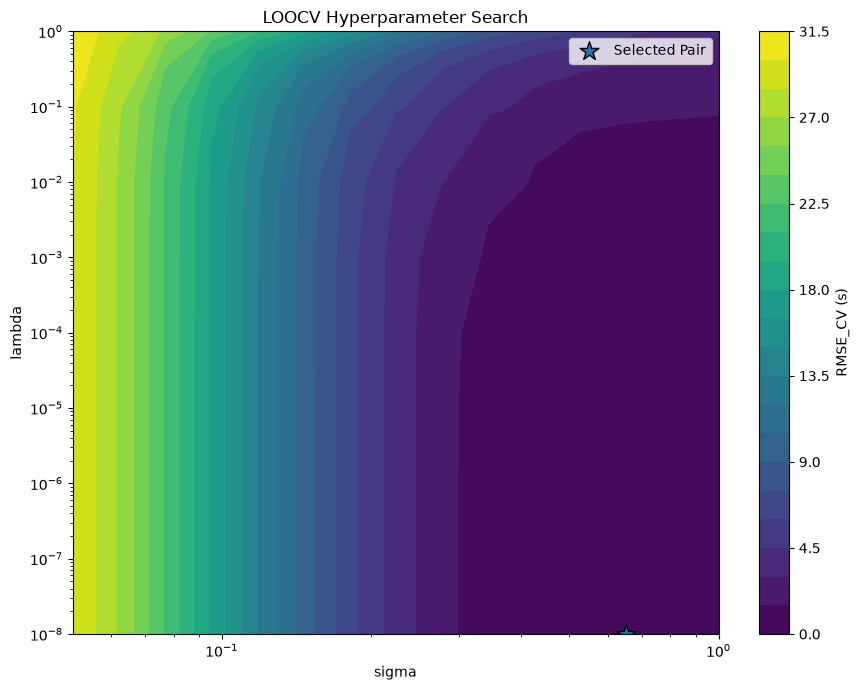

LOOCV predictions for selected model:


,setup_id,rear_wing_angle_deg,rear_ride_height_mm,actual_time_s,predicted_time_s,residual_s,abs_residual_s
0,18,10,45,31.44488,31.440167,0.004713,0.004713
1,13,9,35,31.44076,31.452658,-0.011898,0.011898
2,25,13,35,31.59024,31.366482,0.223758,0.223758
3,2,5,40,32.85104,33.030382,-0.179342,0.179342
4,5,6,40,32.38096,32.336081,0.044879,0.044879
5,6,6,45,32.44690,32.410609,0.036291,0.036291
6,3,5,45,32.99286,33.047647,-0.054787,0.054787
7,16,10,35,31.32624,31.316919,0.009321,0.009321
8,23,12,40,31.35834,31.308303,0.050037,0.050037
9,4,6,35,32.51308,32.576898,-0.063818,0.063818



Setup with largest absolute LOOCV residual:


,setup_id,rear_wing_angle_deg,rear_ride_height_mm,actual_time_s,predicted_time_s,residual_s,abs_residual_s
2,25,13,35,31.59024,31.366482,0.223758,0.223758


Setup with smallest absolute LOOCV residual:


,setup_id,rear_wing_angle_deg,rear_ride_height_mm,actual_time_s,predicted_time_s,residual_s,abs_residual_s
0,18,10,45,31.44488,31.440167,0.004713,0.004713


Largest absolute residual = 0.22375754651148583 s
Smallest absolute residual = 0.004713183841420943 s


In [107]:
# Question 14
# Visualize the LOOCV hyperparameter search

sigma_grid, lam_grid = np.meshgrid(
    sigma_values,
    lam_values,
    indexing="ij"
)

rmse_grid = np.full(
    (len(sigma_values), len(lam_values)),
    np.nan
)

for i, sigma in enumerate(sigma_values):
    for j, lam in enumerate(lam_values):

        match = df_cv_search[
            np.isclose(df_cv_search["sigma"], sigma)
            & np.isclose(df_cv_search["lam"], lam)
        ]

        if (
            len(match) == 1
            and match.iloc[0]["status"] == "success"
            and np.isfinite(match.iloc[0]["RMSE_CV"])
        ):
            rmse_grid[i, j] = match.iloc[0]["RMSE_CV"]


plt.figure(figsize=(9, 7))

contour = plt.contourf(
    sigma_grid,
    lam_grid,
    np.ma.masked_invalid(rmse_grid),
    levels=25
)

cbar = plt.colorbar(contour)
cbar.set_label("RMSE_CV (s)")

plt.scatter(
    sigma_selected,
    lam_selected,
    marker="*",
    s=200,
    edgecolor="black",
    label="Selected Pair"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("sigma")
plt.ylabel("lambda")
plt.title("LOOCV Hyperparameter Search")
plt.legend()
plt.tight_layout()
plt.show()


# Question 15
# Inspect LOOCV predictions for the selected model

y_loocv_selected, PRESS_selected, RMSE_CV_selected = loocv_rbf(
    X_train_norm,
    y_train,
    sigma_selected,
    lam_selected
)

df_loocv_predictions = pd.DataFrame({
    "setup_id": df_train["setup_id"].to_numpy(),
    "rear_wing_angle_deg": df_train["rear_wing_angle_deg"].to_numpy(),
    "rear_ride_height_mm": df_train["rear_ride_height_mm"].to_numpy(),
    "actual_time_s": y_train,
    "predicted_time_s": y_loocv_selected
})

df_loocv_predictions["residual_s"] = (
    df_loocv_predictions["actual_time_s"]
    - df_loocv_predictions["predicted_time_s"]
)

df_loocv_predictions["abs_residual_s"] = (
    df_loocv_predictions["residual_s"].abs()
)

print("LOOCV predictions for selected model:")
display(df_loocv_predictions)

largest_index = df_loocv_predictions[
    "abs_residual_s"
].idxmax()

smallest_index = df_loocv_predictions[
    "abs_residual_s"
].idxmin()

print("\nSetup with largest absolute LOOCV residual:")
display(
    df_loocv_predictions.loc[
        [largest_index]
    ]
)

print("Setup with smallest absolute LOOCV residual:")
display(
    df_loocv_predictions.loc[
        [smallest_index]
    ]
)

print(
    "Largest absolute residual =",
    df_loocv_predictions.loc[
        largest_index,
        "abs_residual_s"
    ],
    "s"
)

print(
    "Smallest absolute residual =",
    df_loocv_predictions.loc[
        smallest_index,
        "abs_residual_s"
    ],
    "s"
)

Question #14 Markdown: 

The contour plot shows how LOOCV RMSE changes with the Gaussian width \(\sigma\) and regularization parameter \(\lambda\). The selected pair corresponds to the lowest successful RMSE_CV found on the specified grid. If the selected point lies on or near an edge of the search domain, this suggests that a wider search range may be worth investigating. If it lies well inside the domain and is surrounded by a relatively broad region of similarly low RMSE_CV values, the result is less sensitive to small changes in the hyperparameters. However, even an interior minimum does not prove that the true continuous optimum lies within the search range because only a finite set of discrete \(\sigma\) and \(\lambda\) values was evaluated.

In [108]:
# Question 16
# Quadratic model LOOCV using normalized training inputs

def quadratic_design_matrix(X):
    X = np.asarray(X, dtype=float)

    z1 = X[:, 0]
    z2 = X[:, 1]

    return np.column_stack([
        np.ones(len(X)),
        z1,
        z2,
        z1**2,
        z2**2,
        z1 * z2
    ])


def loocv_quadratic(X, y):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)

    n = len(y)
    y_pred = np.empty(n, dtype=float)

    for i in range(n):
        mask = np.ones(n, dtype=bool)
        mask[i] = False

        X_fold = X[mask]
        y_fold = y[mask]

        Phi_fold = quadratic_design_matrix(X_fold)

        b_fold, _, _, _ = np.linalg.lstsq(
            Phi_fold,
            y_fold,
            rcond=None
        )

        Phi_omit = quadratic_design_matrix(
            X[i:i+1]
        )

        y_pred[i] = (
            Phi_omit @ b_fold
        )[0]

    residuals = y - y_pred

    PRESS = np.sum(residuals**2)

    RMSE_CV = np.sqrt(
        PRESS / n
    )

    return y_pred, PRESS, RMSE_CV


y_quad_loocv, PRESS_quad, RMSE_CV_quad = loocv_quadratic(
    X_train_norm,
    y_train
)

print("Quadratic PRESS =", PRESS_quad)
print("Quadratic RMSE_CV =", RMSE_CV_quad)


# Question 17
# Compare default RBF, tuned RBF, and quadratic model

_, PRESS_default, RMSE_CV_default = loocv_rbf(
    X_train_norm,
    y_train,
    sigma_default,
    lam_default
)

_, PRESS_tuned, RMSE_CV_tuned = loocv_rbf(
    X_train_norm,
    y_train,
    sigma_selected,
    lam_selected
)

df_model_comparison = pd.DataFrame({
    "model": [
        "Default RBF",
        "Tuned RBF",
        "Quadratic"
    ],
    "RMSE_CV_s": [
        RMSE_CV_default,
        RMSE_CV_tuned,
        RMSE_CV_quad
    ]
})

df_model_comparison = df_model_comparison.sort_values(
    "RMSE_CV_s"
).reset_index(drop=True)

print("\nCross-validation comparison:")
display(df_model_comparison)

best_model = df_model_comparison.loc[0, "model"]
best_rmse = df_model_comparison.loc[0, "RMSE_CV_s"]

print("Lowest RMSE_CV model:", best_model)
print("Lowest RMSE_CV =", best_rmse, "s")

print("\nFrozen tuned RBF hyperparameters:")
print("sigma =", sigma_selected)
print("lambda =", lam_selected)

Quadratic PRESS = 0.014076211285475908
Quadratic RMSE_CV = 0.026529428268882754

Cross-validation comparison:


,model,RMSE_CV_s
0,Quadratic,0.026529
1,Tuned RBF,0.079407
2,Default RBF,5.505476


Lowest RMSE_CV model: Quadratic
Lowest RMSE_CV = 0.026529428268882754 s

Frozen tuned RBF hyperparameters:
sigma = 0.6520572293428615
lambda = 1e-08


Question #17 Markdown: 

The default RBF, tuned RBF, and quadratic models were compared using LOOCV RMSE calculated only from the training configurations. The model with the smallest RMSE_CV provides the best cross-validated predictive performance among the three candidates. The tuned RBF hyperparameters, \(\sigma\) and \(\lambda\), were selected entirely from the training data and are now frozen. The test set will be used only for final model evaluation and will not be used to modify the selected hyperparameters or expand the hyperparameter search range.

,model,sigma,lam,train_RMSE_s,RMSE_CV_s,test_RMSE_s,test_MAE_s,test_R2
0,Default RBF,0.200000,1.000000e-02,0.253362,5.505476,3.169248,2.231456,-29.154571
1,Tuned RBF,0.652057,1.000000e-08,0.000774,0.079407,0.121868,0.086699,0.955412
2,Quadratic,NaN,NaN,0.019241,0.026529,0.025850,0.018986,0.997994


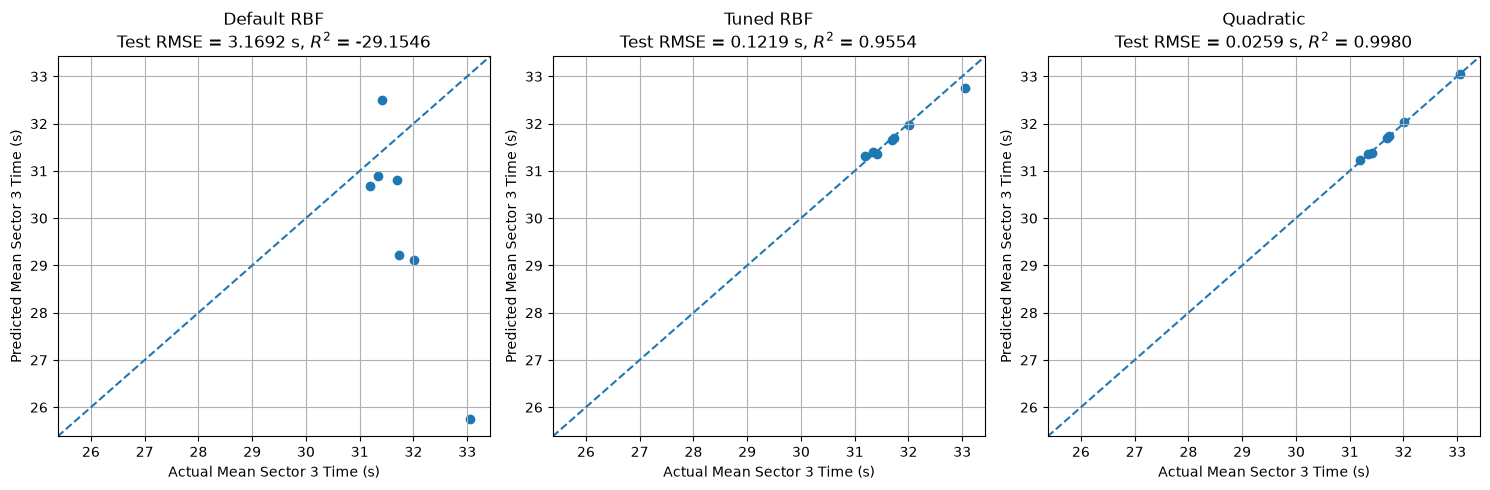

In [109]:
# Question 18
# Fit and validate the default RBF, tuned RBF, and quadratic models

b_default_final = fit_rbf(
    X_train_norm,
    y_train,
    sigma_default,
    lam_default
)

train_pred_default = predict_rbf(
    X_train_norm,
    X_train_norm,
    b_default_final,
    sigma_default
)

test_pred_default = predict_rbf(
    X_test_norm,
    X_train_norm,
    b_default_final,
    sigma_default
)


b_tuned_final = fit_rbf(
    X_train_norm,
    y_train,
    sigma_selected,
    lam_selected
)

train_pred_tuned = predict_rbf(
    X_train_norm,
    X_train_norm,
    b_tuned_final,
    sigma_selected
)

test_pred_tuned = predict_rbf(
    X_test_norm,
    X_train_norm,
    b_tuned_final,
    sigma_selected
)


Phi_train_quad = quadratic_design_matrix(X_train_norm)

b_quad, _, _, _ = np.linalg.lstsq(
    Phi_train_quad,
    y_train,
    rcond=None
)

train_pred_quad = (
    Phi_train_quad @ b_quad
)

Phi_test_quad = quadratic_design_matrix(X_test_norm)

test_pred_quad = (
    Phi_test_quad @ b_quad
)


def rmse(y_actual, y_pred):
    return np.sqrt(
        np.mean((y_actual - y_pred)**2)
    )


def mae(y_actual, y_pred):
    return np.mean(
        np.abs(y_actual - y_pred)
    )


def r_squared(y_actual, y_pred):
    ss_res = np.sum(
        (y_actual - y_pred)**2
    )

    ss_tot = np.sum(
        (y_actual - np.mean(y_actual))**2
    )

    return 1 - (ss_res / ss_tot)


df_validation = pd.DataFrame({
    "model": [
        "Default RBF",
        "Tuned RBF",
        "Quadratic"
    ],

    "sigma": [
        sigma_default,
        sigma_selected,
        np.nan
    ],

    "lam": [
        lam_default,
        lam_selected,
        np.nan
    ],

    "train_RMSE_s": [
        rmse(y_train, train_pred_default),
        rmse(y_train, train_pred_tuned),
        rmse(y_train, train_pred_quad)
    ],

    "RMSE_CV_s": [
        RMSE_CV_default,
        RMSE_CV_tuned,
        RMSE_CV_quad
    ],

    "test_RMSE_s": [
        rmse(y_test, test_pred_default),
        rmse(y_test, test_pred_tuned),
        rmse(y_test, test_pred_quad)
    ],

    "test_MAE_s": [
        mae(y_test, test_pred_default),
        mae(y_test, test_pred_tuned),
        mae(y_test, test_pred_quad)
    ],

    "test_R2": [
        r_squared(y_test, test_pred_default),
        r_squared(y_test, test_pred_tuned),
        r_squared(y_test, test_pred_quad)
    ]
})

display(df_validation)


# Question 19
# Create actual-versus-predicted plots for the test setups

predictions = [
    test_pred_default,
    test_pred_tuned,
    test_pred_quad
]

model_names = [
    "Default RBF",
    "Tuned RBF",
    "Quadratic"
]

all_values = np.concatenate([
    y_test,
    test_pred_default,
    test_pred_tuned,
    test_pred_quad
])

axis_min = all_values.min()
axis_max = all_values.max()

padding = 0.05 * (
    axis_max - axis_min
)

axis_limits = [
    axis_min - padding,
    axis_max + padding
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)

for i, ax in enumerate(axes):

    ax.scatter(
        y_test,
        predictions[i]
    )

    ax.plot(
        axis_limits,
        axis_limits,
        "--"
    )

    ax.set_xlim(axis_limits)
    ax.set_ylim(axis_limits)

    ax.set_xlabel(
        "Actual Mean Sector 3 Time (s)"
    )

    ax.set_ylabel(
        "Predicted Mean Sector 3 Time (s)"
    )

    ax.set_title(
        f"{model_names[i]}\n"
        f"Test RMSE = "
        f"{df_validation.loc[i, 'test_RMSE_s']:.4f} s, "
        f"$R^2$ = "
        f"{df_validation.loc[i, 'test_R2']:.4f}"
    )

    ax.grid(True)

plt.tight_layout()
plt.show()

Question #20: 

Tuning substantially improved the RBF model. The default RBF had an RMSE_CV of approximately 5.5055 s and a test RMSE of 3.1692 s, while the tuned RBF reduced these errors to approximately 0.0794 s and 0.1219 s, respectively. However, the quadratic reference model remained the strongest of the three models, with an RMSE_CV of approximately 0.0265 s and a test RMSE of 0.0259 s. Therefore, the cross-validation ranking and test-set ranking agree: the quadratic model performs best, followed by the tuned RBF, while the default RBF performs worst. The tuned RBF should not automatically be considered the best model simply because its hyperparameters were optimized. Hyperparameter tuning only selects the best RBF candidate within the specified search grid and does not guarantee that it will outperform a different model form. Test error can also differ from the minimum cross-validation error because LOOCV estimates generalization using the training configurations, while the test error is calculated from a separate finite set of unseen configurations. Differences in the particular setups contained in these samples, sampling variability, and model-selection effects can therefore cause the test error to differ from the cross-validation estimate.

Task 5: Response Surfaces and Observation Influence

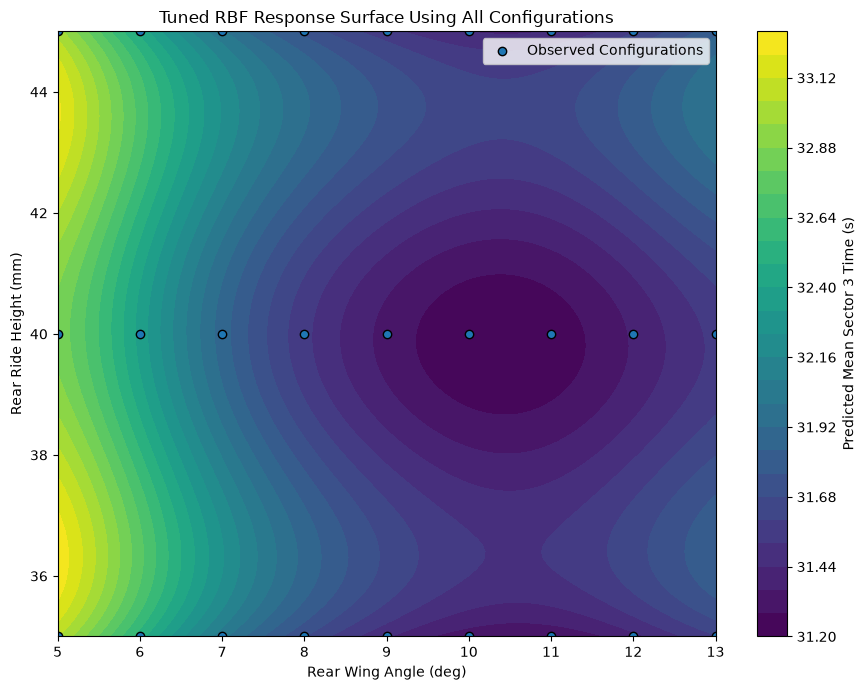

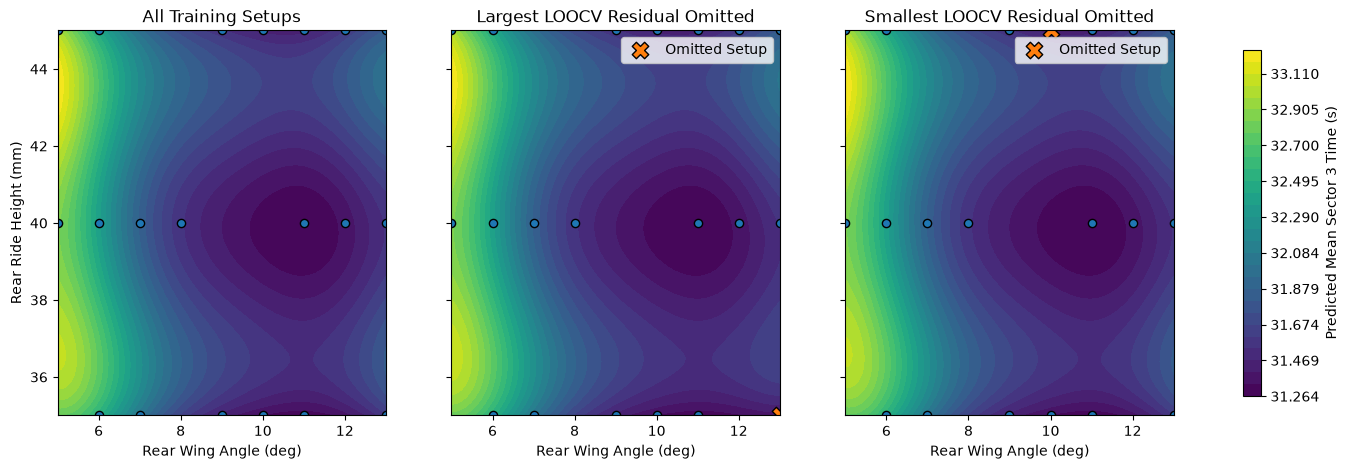

In [110]:
# Question 21
# Refit tuned RBF on all configurations and plot response surface

X_all = df_grouped[
    ["rear_wing_angle_deg", "rear_ride_height_mm"]
].to_numpy()

y_all = df_grouped[
    "mean_sector_3_time_s"
].to_numpy()

X_all_norm = normalize_inputs(X_all)

b_tuned_all = fit_rbf(
    X_all_norm,
    y_all,
    sigma_selected,
    lam_selected
)

wing_grid_values = np.linspace(
    wing_bounds[0],
    wing_bounds[1],
    101
)

ride_grid_values = np.linspace(
    ride_height_bounds[0],
    ride_height_bounds[1],
    101
)

wing_grid, ride_grid = np.meshgrid(
    wing_grid_values,
    ride_grid_values
)

grid_points = np.column_stack([
    wing_grid.ravel(),
    ride_grid.ravel()
])

grid_points_norm = normalize_inputs(
    grid_points
)

grid_predictions_all = predict_rbf(
    grid_points_norm,
    X_all_norm,
    b_tuned_all,
    sigma_selected
)

grid_predictions_all = grid_predictions_all.reshape(
    wing_grid.shape
)

plt.figure(figsize=(9, 7))

contour = plt.contourf(
    wing_grid,
    ride_grid,
    grid_predictions_all,
    levels=30
)

plt.scatter(
    df_grouped["rear_wing_angle_deg"],
    df_grouped["rear_ride_height_mm"],
    edgecolor="black",
    label="Observed Configurations"
)

cbar = plt.colorbar(contour)
cbar.set_label("Predicted Mean Sector 3 Time (s)")

plt.xlabel("Rear Wing Angle (deg)")
plt.ylabel("Rear Ride Height (mm)")
plt.title("Tuned RBF Response Surface Using All Configurations")
plt.legend()
plt.tight_layout()
plt.show()


# Question 22
# Compare full training fit with leave-one-out response surfaces

largest_index = df_loocv_predictions[
    "abs_residual_s"
].idxmax()

smallest_index = df_loocv_predictions[
    "abs_residual_s"
].idxmin()

largest_setup_id = df_loocv_predictions.loc[
    largest_index,
    "setup_id"
]

smallest_setup_id = df_loocv_predictions.loc[
    smallest_index,
    "setup_id"
]

largest_position = np.where(
    df_train["setup_id"].to_numpy() == largest_setup_id
)[0][0]

smallest_position = np.where(
    df_train["setup_id"].to_numpy() == smallest_setup_id
)[0][0]


b_full = fit_rbf(
    X_train_norm,
    y_train,
    sigma_selected,
    lam_selected
)

pred_full = predict_rbf(
    grid_points_norm,
    X_train_norm,
    b_full,
    sigma_selected
).reshape(wing_grid.shape)


mask_largest = np.ones(
    len(X_train_norm),
    dtype=bool
)

mask_largest[largest_position] = False

b_without_largest = fit_rbf(
    X_train_norm[mask_largest],
    y_train[mask_largest],
    sigma_selected,
    lam_selected
)

pred_without_largest = predict_rbf(
    grid_points_norm,
    X_train_norm[mask_largest],
    b_without_largest,
    sigma_selected
).reshape(wing_grid.shape)


mask_smallest = np.ones(
    len(X_train_norm),
    dtype=bool
)

mask_smallest[smallest_position] = False

b_without_smallest = fit_rbf(
    X_train_norm[mask_smallest],
    y_train[mask_smallest],
    sigma_selected,
    lam_selected
)

pred_without_smallest = predict_rbf(
    grid_points_norm,
    X_train_norm[mask_smallest],
    b_without_smallest,
    sigma_selected
).reshape(wing_grid.shape)


color_min = min(
    pred_full.min(),
    pred_without_largest.min(),
    pred_without_smallest.min()
)

color_max = max(
    pred_full.max(),
    pred_without_largest.max(),
    pred_without_smallest.max()
)

levels = np.linspace(
    color_min,
    color_max,
    30
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

plots = [
    pred_full,
    pred_without_largest,
    pred_without_smallest
]

titles = [
    "All Training Setups",
    "Largest LOOCV Residual Omitted",
    "Smallest LOOCV Residual Omitted"
]

for ax, predictions, title in zip(
    axes,
    plots,
    titles
):
    contour = ax.contourf(
        wing_grid,
        ride_grid,
        predictions,
        levels=levels,
        vmin=color_min,
        vmax=color_max
    )

    ax.scatter(
        df_train["rear_wing_angle_deg"],
        df_train["rear_ride_height_mm"],
        edgecolor="black",
        s=35
    )

    ax.set_xlabel("Rear Wing Angle (deg)")
    ax.set_title(title)

axes[0].set_ylabel(
    "Rear Ride Height (mm)"
)

axes[1].scatter(
    X_train[largest_position, 0],
    X_train[largest_position, 1],
    marker="X",
    s=140,
    edgecolor="black",
    label="Omitted Setup"
)

axes[2].scatter(
    X_train[smallest_position, 0],
    X_train[smallest_position, 1],
    marker="X",
    s=140,
    edgecolor="black",
    label="Omitted Setup"
)

axes[1].legend()
axes[2].legend()

cbar = fig.colorbar(
    contour,
    ax=axes,
    shrink=0.9
)

cbar.set_label(
    "Predicted Mean Sector 3 Time (s)"
)

plt.show()

Question #23 Markdown: 

The Gaussian RBF model is controlled primarily by the hyperparameters \(\sigma\) and \(\lambda\). The parameter \(\sigma\) determines the width of each Gaussian basis function. A small \(\sigma\) produces narrow, highly localized basis functions that allow the response surface to change rapidly near individual training configurations, while a larger \(\sigma\) produces a smoother and more broadly varying surface. The regularization parameter \(\lambda\) controls how strongly the fitted RBF weights are constrained. Very small values allow the model to fit the training observations closely, while larger values generally produce a smoother and more stable model at the cost of increased training error.

Minimizing training RMSE is not an appropriate method for choosing these hyperparameters because a highly flexible RBF can reproduce the training observations very accurately without necessarily predicting unseen configurations well. LOOCV provides a better estimate of predictive performance because each setup is omitted in turn and predicted using a model fitted only to the remaining configurations. Therefore, the selected \(\sigma\) and \(\lambda\) were chosen by minimizing RMSE_CV rather than training RMSE.

The LOOCV error contours show how prediction error varies throughout the tested hyperparameter grid. The location and width of the low-error region indicate how sensitive model performance is to changes in \(\sigma\) and \(\lambda\). A broad low-error region suggests that similar nearby hyperparameters produce comparable results, while a narrow minimum indicates greater sensitivity. The contour search is limited to the specified discrete grid, so it does not prove that a better combination does not exist outside the tested range.

The leave-one-out response-surface plots also demonstrate that individual observations can influence the fitted RBF differently. Omitting the setup with the largest LOOCV residual can noticeably change the surface near that configuration, while omitting a well-predicted setup generally causes a smaller local change. However, a large omitted-point prediction error does not necessarily imply a large change across the entire response surface. Its influence may remain localized because Gaussian basis functions are spatially weighted by distance.

Question #24 Markdown: 

Based on the cross-validation and independent test results, I recommend the quadratic model rather than the tuned RBF for predicting mean Sector 3 time. The tuned RBF substantially improved over the default RBF, reducing RMSE_CV to approximately 0.0794 s and test RMSE to approximately 0.1219 s. However, the quadratic model performed better on both measures, with an RMSE_CV of approximately 0.0265 s and a test RMSE of approximately 0.0259 s. The agreement between the cross-validation and test rankings provides additional support for selecting the quadratic model.

This conclusion is still subject to several limitations. The available setup configurations provide relatively sparse coverage of the two-dimensional design region, and the setup means contain normal experimental and lap-to-lap variability. The RBF hyperparameter search was also limited to the prescribed \(\sigma\) and \(\lambda\) grids, so the selected RBF is only the best candidate within that search region. Numerical conditioning can also become important for RBF models when basis functions overlap strongly or regularization becomes very small.

After the test evaluation is completed, refitting a model using all configurations improves the amount of information available for the final response surface, but it also means there is no longer an independent test set available to evaluate that refitted model. Therefore, the all-data surface should be viewed as a model-based predictive surface rather than independently verified performance. Finally, this project models Sector 3 time only. The location of the predicted minimum does not automatically represent the physical optimum of the vehicle because other engineering requirements, including the Project 2 top-speed constraint, are not included in this optimization.

Task 6: Neural Networks with CSV Lap Time Data

In [111]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Question 25
# Load the lap-time CSV and prepare the data

df_lap = pd.read_csv("simulated_laptime_data.csv")

print("First five rows:")
display(df_lap.head())

print("\nDescriptive statistics:")
display(df_lap.describe())

print("\nRow count:")
print(len(df_lap))

print("\nMissing values:")
print(df_lap.isna().sum())

input_columns = [
    "fuel_kg",
    "tire_age_laps"
]

target_column = "time_s"

df_lap["row_id"] = df_lap.index

X = df_lap[input_columns].to_numpy(dtype=float)
y = df_lap[target_column].to_numpy(dtype=float)
row_ids = df_lap["row_id"].to_numpy()


# Question 26
# Split the data and normalize inputs using training bounds

X_train, X_test, y_train, y_test, row_id_train, row_id_test = train_test_split(
    X,
    y,
    row_ids,
    test_size=0.25,
    random_state=42
)

input_min = X_train.min(axis=0)
input_max = X_train.max(axis=0)

X_train_norm = (
    (X_train - input_min)
    / (input_max - input_min)
)

X_test_norm = (
    (X_test - input_min)
    / (input_max - input_min)
)

print("\nTraining observations:")
print(len(X_train))

print("\nTest observations:")
print(len(X_test))

print("\nNormalization bounds from training data:")

for i, column in enumerate(input_columns):
    print(
        f"{column}: "
        f"min = {input_min[i]:.4f}, "
        f"max = {input_max[i]:.4f}"
    )

print("\nX_train_norm shape:", X_train_norm.shape)
print("X_test_norm shape:", X_test_norm.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

First five rows:


,fuel_kg,tire_age_laps,time_s
0,22.189146,7.846392,64.810266
1,29.207419,5.174721,65.917722
2,16.306554,10.407846,65.457985
3,29.178391,7.585621,65.778464
4,18.989303,9.723292,65.446376



Descriptive statistics:


,fuel_kg,tire_age_laps,time_s
count,100.000000,100.000000,100.000000
mean,22.209104,6.037854,65.101500
std,4.615793,3.263998,0.964395
min,14.093194,0.200674,63.108675
25%,18.199190,3.511454,64.372019
50%,22.223122,5.598018,65.020940
75%,26.468585,9.008879,65.619956
max,29.691795,11.988311,67.987389



Row count:
100

Missing values:
fuel_kg          0
tire_age_laps    0
time_s           0
dtype: int64

Training observations:
75

Test observations:
25

Normalization bounds from training data:
fuel_kg: min = 14.0932, max = 29.6918
tire_age_laps: min = 0.2019, max = 11.9883

X_train_norm shape: (75, 2)
X_test_norm shape: (25, 2)
y_train shape: (75,)
y_test shape: (25,)


ReLU convergence warning:
None
ReLU n_iter_ = 360

Tanh convergence warning:
None
Tanh n_iter_ = 1705


,model,activation,train_RMSE_s,test_RMSE_s,test_MAE_s,test_R2,n_iter
0,MLP ReLU,relu,0.430842,0.550548,0.414171,0.693431,360.0
1,MLP Tanh,tanh,0.310246,0.405922,0.263007,0.833344,1705.0
2,Quadratic,,0.535688,0.590557,0.431262,0.647255,NaN


Saved: Aramthun_pr03_laptime_metrics.csv


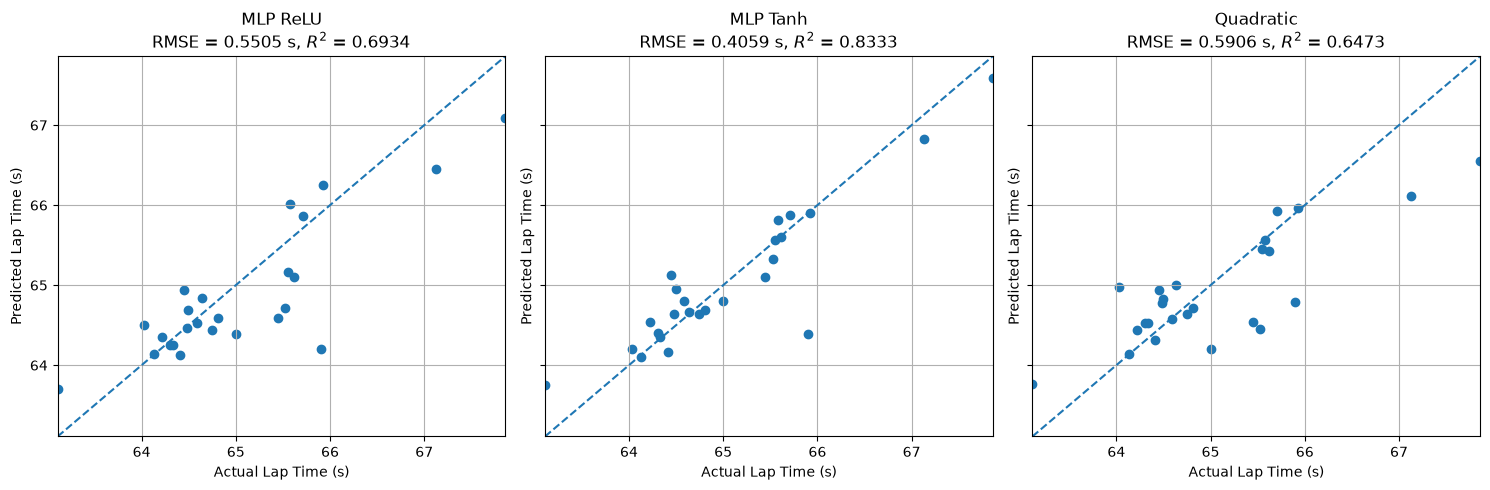

Saved: Aramthun_pr03_laptime_predictions.png


In [112]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.exceptions import ConvergenceWarning


# Question 27
# Train ReLU and tanh MLP models

lap_input_columns = [
    "fuel_kg",
    "tire_age_laps"
]

lap_X = df_lap[lap_input_columns].to_numpy(dtype=float)
lap_y = df_lap["time_s"].to_numpy(dtype=float)
lap_row_ids = df_lap["row_id"].to_numpy()

(
    lap_X_train,
    lap_X_test,
    lap_y_train,
    lap_y_test,
    lap_row_id_train,
    lap_row_id_test
) = train_test_split(
    lap_X,
    lap_y,
    lap_row_ids,
    test_size=0.25,
    random_state=42
)

lap_input_min = lap_X_train.min(axis=0)
lap_input_max = lap_X_train.max(axis=0)

lap_X_train_norm = (
    (lap_X_train - lap_input_min)
    / (lap_input_max - lap_input_min)
)

lap_X_test_norm = (
    (lap_X_test - lap_input_min)
    / (lap_input_max - lap_input_min)
)

lap_X_all_norm = (
    (lap_X - lap_input_min)
    / (lap_input_max - lap_input_min)
)


def fit_mlp_and_report(activation):
    model = MLPRegressor(
        hidden_layer_sizes=(20, 20),
        activation=activation,
        solver="lbfgs",
        alpha=0.1,
        max_iter=5000,
        random_state=1
    )

    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter(
            "always",
            ConvergenceWarning
        )

        model.fit(
            lap_X_train_norm,
            lap_y_train
        )

    convergence_warnings = [
        str(w.message)
        for w in caught_warnings
        if issubclass(w.category, ConvergenceWarning)
    ]

    return model, convergence_warnings


lap_relu_model, lap_relu_warnings = fit_mlp_and_report(
    "relu"
)

lap_tanh_model, lap_tanh_warnings = fit_mlp_and_report(
    "tanh"
)

print("ReLU convergence warning:")
print(
    lap_relu_warnings[0]
    if lap_relu_warnings
    else "None"
)

print("ReLU n_iter_ =", lap_relu_model.n_iter_)

print("\nTanh convergence warning:")
print(
    lap_tanh_warnings[0]
    if lap_tanh_warnings
    else "None"
)

print("Tanh n_iter_ =", lap_tanh_model.n_iter_)


# Question 28
# Fit quadratic reference model and evaluate all three models

lap_Phi_train = quadratic_design_matrix(
    lap_X_train_norm
)

lap_Phi_test = quadratic_design_matrix(
    lap_X_test_norm
)

lap_Phi_all = quadratic_design_matrix(
    lap_X_all_norm
)

lap_b_quadratic, _, _, _ = np.linalg.lstsq(
    lap_Phi_train,
    lap_y_train,
    rcond=None
)

lap_relu_train_pred = lap_relu_model.predict(
    lap_X_train_norm
)

lap_relu_test_pred = lap_relu_model.predict(
    lap_X_test_norm
)

lap_tanh_train_pred = lap_tanh_model.predict(
    lap_X_train_norm
)

lap_tanh_test_pred = lap_tanh_model.predict(
    lap_X_test_norm
)

lap_quad_train_pred = (
    lap_Phi_train @ lap_b_quadratic
)

lap_quad_test_pred = (
    lap_Phi_test @ lap_b_quadratic
)


def lap_rmse(actual, predicted):
    return np.sqrt(
        np.mean((actual - predicted)**2)
    )


def lap_mae(actual, predicted):
    return np.mean(
        np.abs(actual - predicted)
    )


def lap_r2(actual, predicted):
    ss_res = np.sum(
        (actual - predicted)**2
    )

    ss_tot = np.sum(
        (actual - np.mean(actual))**2
    )

    return 1 - ss_res / ss_tot


df_laptime_validation = pd.DataFrame({
    "model": [
        "MLP ReLU",
        "MLP Tanh",
        "Quadratic"
    ],

    "activation": [
        "relu",
        "tanh",
        ""
    ],

    "train_RMSE_s": [
        lap_rmse(
            lap_y_train,
            lap_relu_train_pred
        ),
        lap_rmse(
            lap_y_train,
            lap_tanh_train_pred
        ),
        lap_rmse(
            lap_y_train,
            lap_quad_train_pred
        )
    ],

    "test_RMSE_s": [
        lap_rmse(
            lap_y_test,
            lap_relu_test_pred
        ),
        lap_rmse(
            lap_y_test,
            lap_tanh_test_pred
        ),
        lap_rmse(
            lap_y_test,
            lap_quad_test_pred
        )
    ],

    "test_MAE_s": [
        lap_mae(
            lap_y_test,
            lap_relu_test_pred
        ),
        lap_mae(
            lap_y_test,
            lap_tanh_test_pred
        ),
        lap_mae(
            lap_y_test,
            lap_quad_test_pred
        )
    ],

    "test_R2": [
        lap_r2(
            lap_y_test,
            lap_relu_test_pred
        ),
        lap_r2(
            lap_y_test,
            lap_tanh_test_pred
        ),
        lap_r2(
            lap_y_test,
            lap_quad_test_pred
        )
    ],

    "n_iter": [
        lap_relu_model.n_iter_,
        lap_tanh_model.n_iter_,
        None
    ]
})

display(df_laptime_validation)

df_laptime_validation.to_csv(
    "Aramthun_pr03_laptime_metrics.csv",
    index=False
)

print(
    "Saved: Aramthun_pr03_laptime_metrics.csv"
)


# Question 29
# Save predictions and create actual-versus-predicted panels

lap_model_names = ["MLP ReLU", "MLP Tanh", "Quadratic"]

lap_test_predictions = [
    lap_relu_test_pred,
    lap_tanh_test_pred,
    lap_quad_test_pred
]

lap_plot_values = np.concatenate([lap_y_test, *lap_test_predictions])
lap_axis_limits = [
    lap_plot_values.min(),
    lap_plot_values.max()
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5),
    sharex=True,
    sharey=True
)

for i, ax in enumerate(axes):

    ax.scatter(
        lap_y_test,
        lap_test_predictions[i]
    )

    ax.plot(
        lap_axis_limits,
        lap_axis_limits,
        "--"
    )

    ax.set_xlim(lap_axis_limits)
    ax.set_ylim(lap_axis_limits)

    ax.set_xlabel("Actual Lap Time (s)")
    ax.set_ylabel("Predicted Lap Time (s)")

    ax.set_title(
        f"{lap_model_names[i]}\n"
        f"RMSE = {df_laptime_validation.loc[i, 'test_RMSE_s']:.4f} s, "
        f"$R^2$ = {df_laptime_validation.loc[i, 'test_R2']:.4f}"
    )

    ax.grid(True)

plt.tight_layout()

plt.savefig(
    "Aramthun_pr03_laptime_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: Aramthun_pr03_laptime_predictions.png")

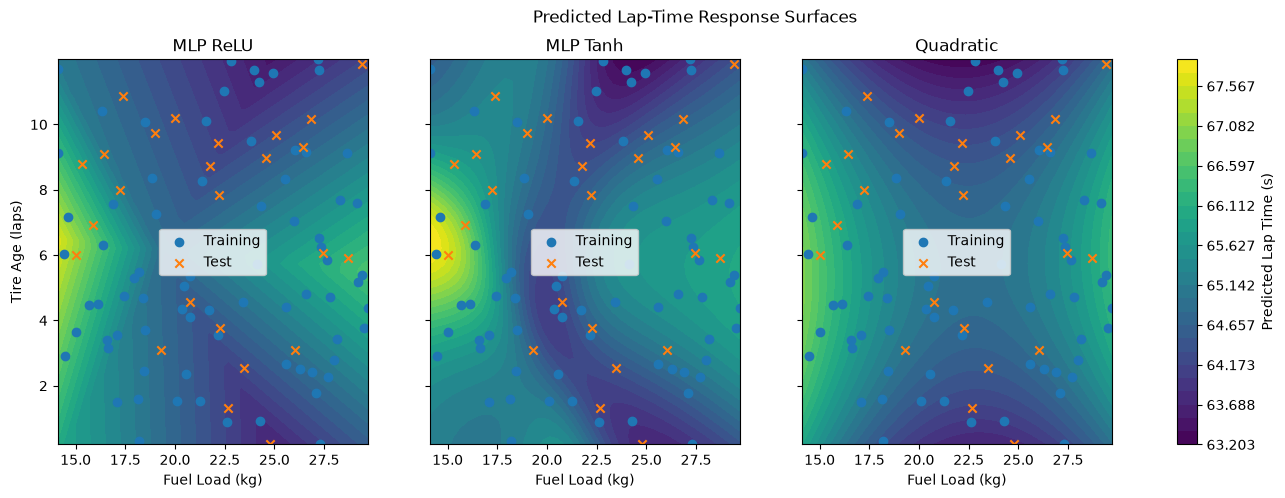

Saved: Aramthun_pr03_laptime_surfaces.png


In [113]:
# Question 30
# Plot neural-network and quadratic lap-time response surfaces

fuel_grid = np.linspace(
    df_lap["fuel_kg"].min(),
    df_lap["fuel_kg"].max(),
    50
)

tire_grid = np.linspace(
    df_lap["tire_age_laps"].min(),
    df_lap["tire_age_laps"].max(),
    50
)

fuel_mesh, tire_mesh = np.meshgrid(
    fuel_grid,
    tire_grid
)

X_grid = np.column_stack([
    fuel_mesh.ravel(),
    tire_mesh.ravel()
])

X_grid_norm = (
    (X_grid - lap_input_min)
    / (lap_input_max - lap_input_min)
)

relu_grid_pred = lap_relu_model.predict(
    X_grid_norm
).reshape(fuel_mesh.shape)

tanh_grid_pred = lap_tanh_model.predict(
    X_grid_norm
).reshape(fuel_mesh.shape)

quad_grid_pred = (
    quadratic_design_matrix(X_grid_norm)
    @ lap_b_quadratic
).reshape(fuel_mesh.shape)

surface_min = min(
    relu_grid_pred.min(),
    tanh_grid_pred.min(),
    quad_grid_pred.min()
)

surface_max = max(
    relu_grid_pred.max(),
    tanh_grid_pred.max(),
    quad_grid_pred.max()
)

levels = np.linspace(
    surface_min,
    surface_max,
    30
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5),
    sharex=True,
    sharey=True
)

surface_predictions = [
    relu_grid_pred,
    tanh_grid_pred,
    quad_grid_pred
]

surface_titles = [
    "MLP ReLU",
    "MLP Tanh",
    "Quadratic"
]

for ax, prediction, title in zip(
    axes,
    surface_predictions,
    surface_titles
):
    contour = ax.contourf(
        fuel_mesh,
        tire_mesh,
        prediction,
        levels=levels
    )

    ax.scatter(
        lap_X_train[:, 0],
        lap_X_train[:, 1],
        marker="o",
        label="Training"
    )

    ax.scatter(
        lap_X_test[:, 0],
        lap_X_test[:, 1],
        marker="x",
        label="Test"
    )

    ax.set_xlabel("Fuel Load (kg)")
    ax.set_title(title)
    ax.legend()

axes[0].set_ylabel("Tire Age (laps)")

cbar = fig.colorbar(
    contour,
    ax=axes,
    label="Predicted Lap Time (s)"
)

fig.suptitle(
    "Predicted Lap-Time Response Surfaces"
)

plt.savefig(
    "Aramthun_pr03_laptime_surfaces.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: Aramthun_pr03_laptime_surfaces.png")

Question #31 Markdown

The ReLU and tanh activation functions produce noticeably different lap-time response surfaces. ReLU is piecewise linear, so its surface can contain sharper changes or transitions between regions. Tanh is smooth and continuously differentiable, which generally produces a smoother response surface. For this dataset, the tanh MLP produced the lowest test RMSE at approximately 0.2810 s, compared with approximately 0.6786 s for ReLU and 0.5906 s for the quadratic model. Therefore, the smoother tanh surface also provided the best test prediction in this particular split. However, smoothness alone does not guarantee better predictive performance, as shown by the smooth quadratic model performing worse than tanh.

The neural-network weights and biases are learned from the 75 training observations during model fitting. In contrast, the architecture `(20, 20)`, activation function, `alpha=0.1`, L-BFGS solver, maximum iteration count, and random seed are fixed modeling choices rather than learned parameters.

These results should also be interpreted cautiously because they come from one 75/25 train-test split. A different split could produce different error rankings, especially with only 100 observations. Predictions in sparsely sampled regions of fuel load and tire age are also less strongly supported by data. Therefore, the tanh network is the strongest model for this required comparison, but the results do not establish that tanh, ReLU, or any other model family is universally best.